# Machine Learning for Sound and Music 2026
## Lab 1: Music Genre Classification
##### Author: Lidia Wiśniewska
-----
### Background
Automatic genre classification using machine learning techniques is pivotal in managing
and enriching large-scale text and music collections. In textual data, assigning genre
labels—such as promotional or legal—enhances information retrieval by enabling users
to filter documents based on their specific needs, thereby improving search relevance and
efficiency. This automated labeling also aids in the curation of web corpora, ensuring a
diverse and representative dataset for training language models, which is essential for
advancing natural language processing applications. 

In the realm of music, genre classification facilitates the organization of extensive audio libraries, supporting
personalized recommendation systems and efficient content-based music retrieval. By
analyzing audio features, machine learning models can accurately categorize tracks into
genres like classical, jazz, or hip-hop, enhancing user experience in music streaming
services. Overall, the integration of automatic genre classification streamlines the
management of vast information repositories, making them more accessible and user-
centric

---
### Approach
This notebook implements genre classification using tradiitonal ML techniques:
* Logistic Regression
* kNN
* Decision Trees
* Random Forest
* ANN

---
### Structure
The notebook structure looks as follows: <br>
1. [Task 1](#task-1)<br>
    1. [Data loading](#1-data-loading-and-eda)<br>
    2. [Feature engineering](#2-feature-engineering)<br>
    3. [Classification](#3-classification)<br>
    4. [Evaluation](#4-evaluation)<br>
    5. [Research questions]()<br>
2. [Task 2](#task-2)<br>
    1. Data loading]()
    2. [Feature engineering]()<br>
    3. [Classification]()<br>
    4. [Evaluation]()<br>
    5. [Research questions]()<br>
    



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 250)

# Task 1

## 1. Data loading and EDA

In [ ]:
genre_df = pd.read_csv("./data/GenreAll.csv", sep=",")
genre_df.columns = genre_df.columns.str.strip() #erase the whitespaces
feature_colnames = genre_df.columns.drop('genre').tolist()

print(f"Shape: {genre_df.shape[0]} rows, {genre_df.shape[1]} columns\n")
genre_df.head(10)

Shape: 993 rows, 241 columns



,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean

#### Missing values and duplicates

In [3]:
missing_counts = genre_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

print("Missing values by column:")
if missing_counts.empty:
    print("No missing values found.")
else:
    print(missing_counts.to_string())

Missing values by column:
No missing values found.


In [4]:
#check the duplicates only of feature columns to inspect possible mislabeling
duplicate_rows = genre_df[genre_df.duplicated(subset=feature_colnames, keep=False)] #keeping all versions to inspect

print(f"\nDuplicate rows found: {len(duplicate_rows)}")
duplicate_rows.sort_values(by=feature_colnames[:5])


Duplicate rows found: 28


,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean

We have 14 pairs of duplicates, in which 1 pair is mislabeled (the same sample has 2 different genres). As we can't listen to the samples, the safest is to discard both entries, while for the rest of the 13 pairs to keep the first occurence.

In [5]:
genre_counts = genre_df.groupby(feature_colnames)['genre'].transform('nunique')
safe_df = genre_df[genre_counts == 1]
genre_df = safe_df.drop_duplicates(subset=feature_colnames, keep='first').reset_index(drop=True)

print(f"Shape: {genre_df.shape[0]} rows, {genre_df.shape[1]} columns\n")
genre_df.head(5)

Shape: 978 rows, 241 columns



,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean

#### Datatypes

In [6]:
print(f"Unique data types: {genre_df.dtypes.unique().tolist()}")
print("\nAll column data types:\n")
genre_df.dtypes

Unique data types: [dtype('float64'), <StringDtype(storage='python', na_value=nan)>, dtype('int64')]

All column data types:



highlevel_danceability_value                   float64
highlevel_equalization_profile_value           float64
highlevel_excitement_value                     float64
highlevel_intensity_value                      float64
highlevel_speech_music_value                       str
                                                ...   
tonal_dissonance_var                           float64
tonal_key_mode_value                               str
tonal_key_strength_value                       float64
tonal_tuning_equal_tempered_deviation_value    float64
genre                                              str
Length: 241, dtype: object

As we can see we have mostly numeric (float) data with ocasional strings and integers.

In [7]:
cat_columns = genre_df.select_dtypes(include='string').columns
num_columns = genre_df.select_dtypes(include="number").columns

assert len(num_columns)+len(cat_columns)==genre_df.shape[1], "You just lost some columns..."

#### Numerical columns

In [8]:
feature_df_descr = genre_df[num_columns].describe()
feature_df_descr

,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean,spectral_mfcc_00_var,spectral_mfcc_01_dvar,spectral_mfcc_01_mea

Most of the features are centered around 0 and have std close to 1, meaning they are standardized. However, the ranges differ and the features will require some normalization later on.

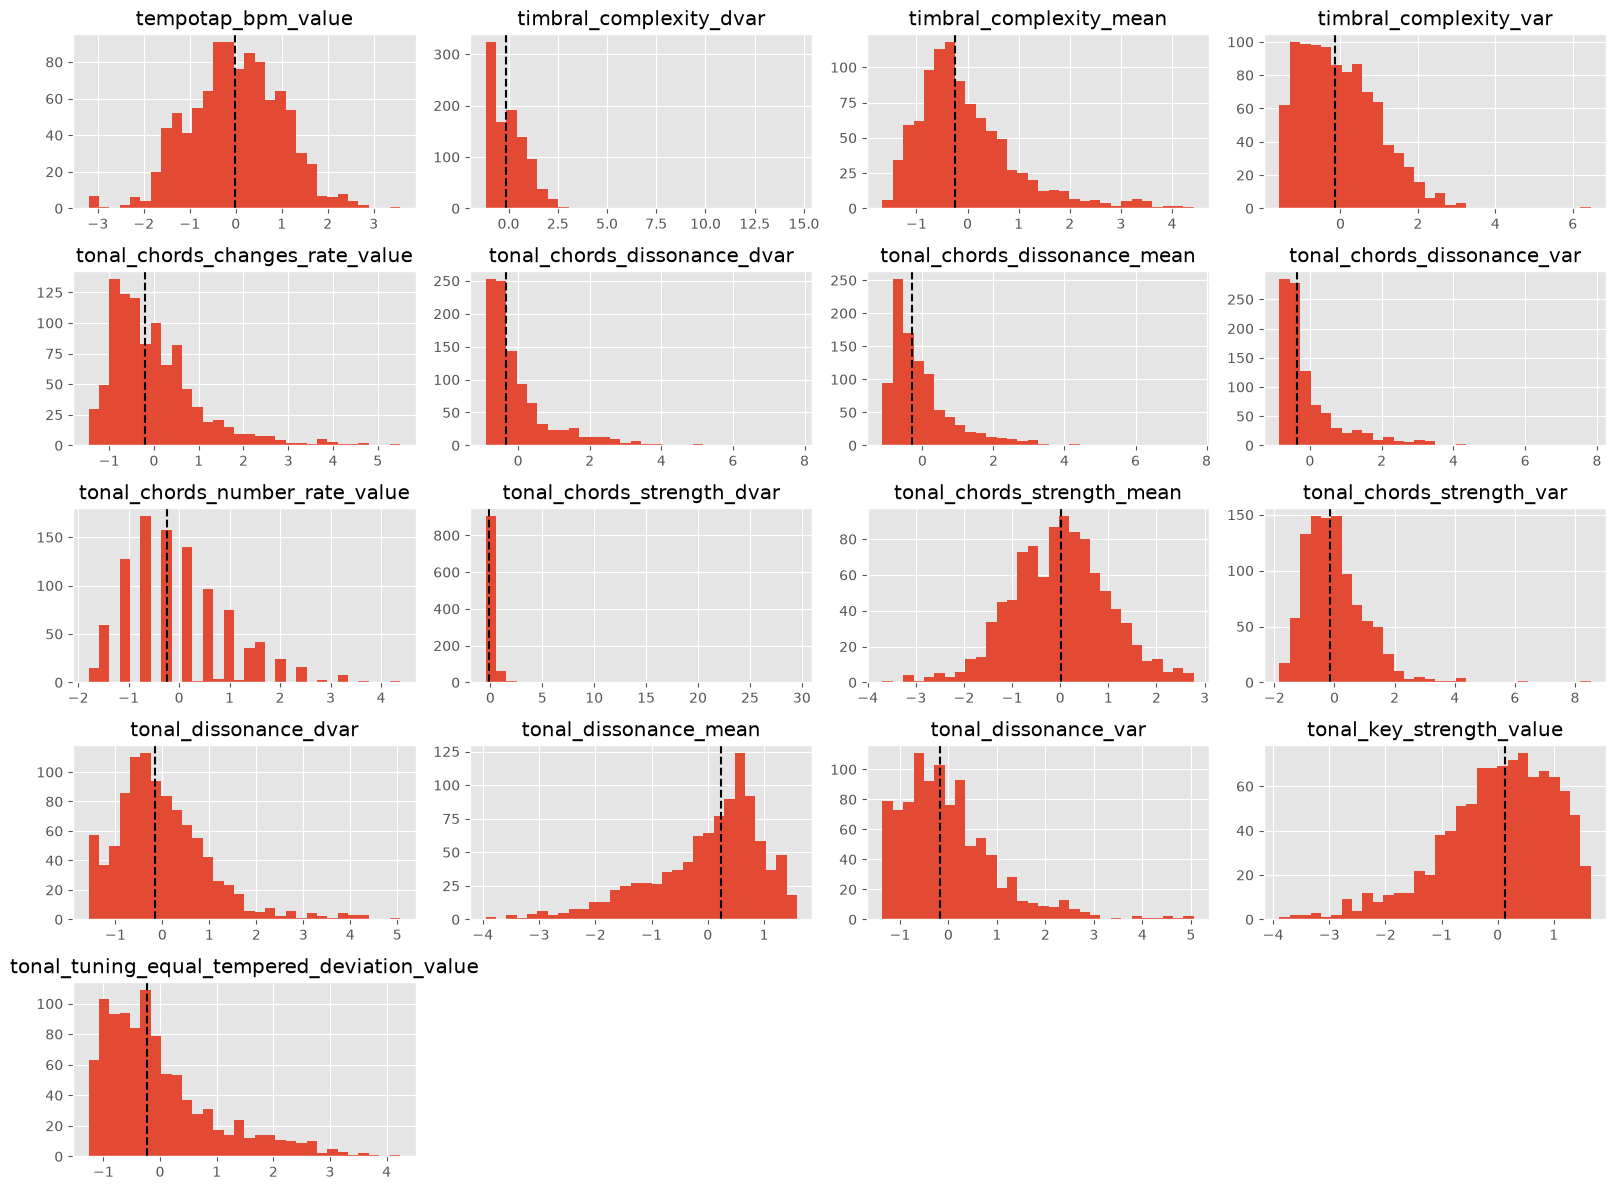

In [9]:
#distributions
with PdfPages("./data/task1_distributions.pdf") as pdf:
    for start in range(0, len(num_columns), 20):
        cols=num_columns[start:start+20]
        axes = genre_df[num_columns][cols].hist(bins=30, figsize=(16, 12))

        for ax, col in zip(axes.ravel(), cols):
            median = feature_df_descr.loc["50%", col]
            ax.axvline(median, color="black", linestyle="--", linewidth=1.5)
        fig = axes.ravel()[0].figure
        fig.tight_layout()
        pdf.savefig(fig)

        if start + 20 < len(num_columns):
            plt.close(fig)
        last_fig = fig

if last_fig is not None:
    plt.show()

The plots don't support the standardization of the data, however show that many columns represent different statistics of the same feature, e.g. for tonal_dissonance we have 3 columns: dvar, mean and var. Additionally we are working with many different distributions and skewness levels. Additionally, after inspecting the rest of the plots (saved in a file), we can observe that most of the `_var` and `_dvar` features are not really spread, meaning they are concentrated around 0 and do not go very far from that value.

In [10]:
#variance check
feature_df_descr.iloc[2, :].sort_values(ascending=True).head(5)


spectral_barkbands_25_var          0.000000
spectral_barkbands_25_dvar         0.000000
rhythm_beats_loudness_bass_dvar    0.978101
spectral_barkbands_16_mean         0.984197
spectral_strongpeak_var            0.985805
Name: std, dtype: float64

This shows that features `spectral_barkbands_25_var` and `spectral_barkbands_25_dvar` have std of 0, so are basically constant features and are redundant.

In [11]:
col_to_drop = feature_df_descr.iloc[2, :].sort_values(ascending=True).head(2).index.astype(str).tolist()
num_columns = num_columns.drop(col_to_drop)
genre_df.drop(col_to_drop, axis=1, inplace=True)
genre_df.shape

(978, 239)

In [12]:
#mean check
feature_df_descr.iloc[1, :].sort_values(ascending=False).head(5)
mean_max = feature_df_descr.iloc[1, :].max()
mean_min = feature_df_descr.iloc[1, :].min()
print(f"The highest mean value: {mean_max}, the lowest mean value: {mean_min}")


The highest mean value: 0.012395018404907957, the lowest mean value: -0.01760213803680981


In [13]:
#min check
feature_df_descr.iloc[3, :].sort_values(ascending=True).head(5)

loudness_vicker_mean    -5.653249
spectral_mfcc_11_mean   -4.842011
spectral_mfcc_10_mean   -4.774977
spectral_mfcc_09_mean   -4.772353
loudness_larm_mean      -4.734653
Name: min, dtype: float64

In [14]:
#max check
feature_df_descr.iloc[7, :].sort_values(ascending=False).head(10)

tonal_chords_strength_dvar         29.521946
spectral_mfcc_03_dvar              28.574514
spectral_barkbands_14_var          27.077678
spectral_barkbands_22_var          25.743854
loudness_larm_var                  25.411209
spectral_barkbands_06_var          25.137454
spectral_barkbands_00_dvar         24.500464
spectral_silence_rate_60dB_dvar    24.430404
spectral_barkbands_20_dvar         23.945951
spectral_barkbands_05_dvar         23.847306
Name: max, dtype: float64

We can observe that the minimal values start around -5 and the maximal values are up to even 29. At first glance they don't look like outliers.

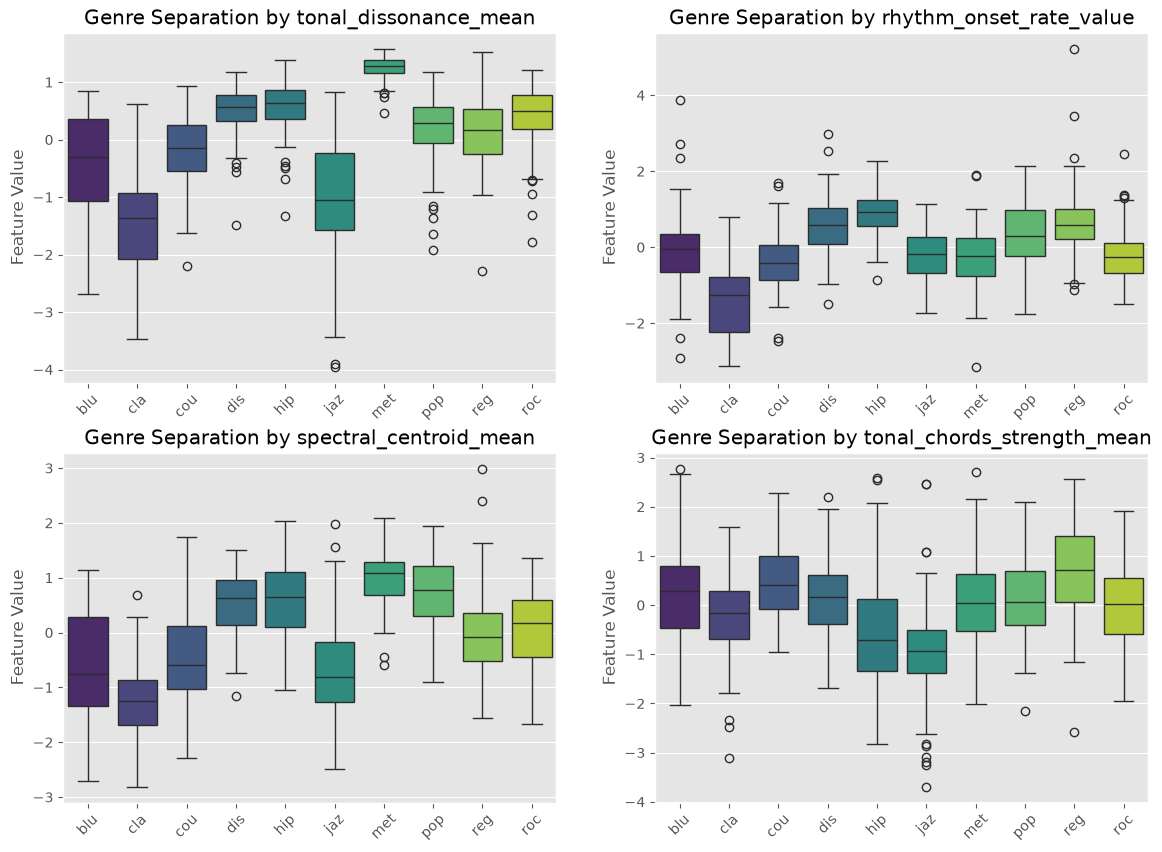

In [15]:
#primary target separation inspection

to_inspect = ["tonal_dissonance_mean",
              "rhythm_onset_rate_value",
              "spectral_centroid_mean",
              "tonal_chords_strength_mean",
              ]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(to_inspect):
    sns.boxplot(data=genre_df, x='genre', y=feature, ax=axes[i], hue="genre",legend=False, palette='viridis')
    axes[i].set_title(f'Genre Separation by {feature}')
    axes[i].set_ylabel('Feature Value')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.show()

By taking random features we can observe that complete target separation was not possible (which would be a miracle having randomly chosen the features and 10 distinct classes). Yet, noticeable is some grouping of families/separation based on characteristics a specific feature has measured.

Starting with `tonal_dissonance_mean` feature  we can observe that it heavily isolates metal at the extreme top, while grouping jazz and classical together at the very bottom. On the other hand, `rhythm_onset_rate_value` groups groove-centric genres like hip-hop, disco, and reggae high up the scale, putting classical completely separate at the lowest end. 

Looking at `spectral_centroid_mean`, it groups together classical, blues, jazz and country, while hiphop, metal and pop stand together. Finally, we can observe that `tonal_chords_strength_mean` clearly separates reggae by placing it at the top, while clustering hip-hop and jazz together in the negative values because their harmonies are too complex (jazz) or buried under the beat (hip-hop).

Additionally, we should notice the presence of outliers depending on the feature/category combination. This should be adressed in the future.
 


Reduced heatmap from 235 down to 64 highly correlated features.


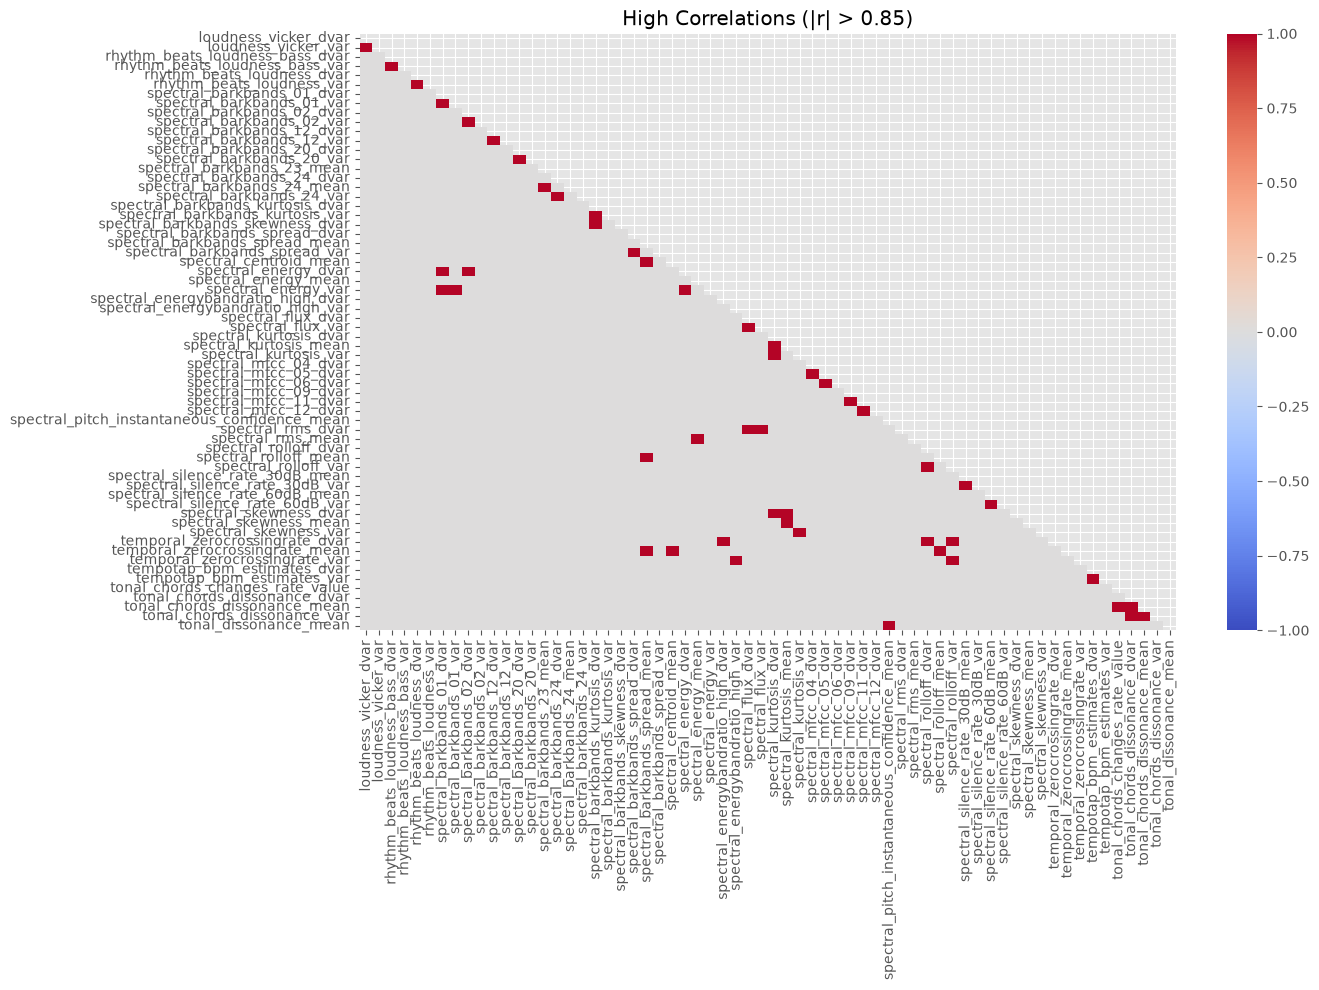

In [16]:
# heatmaps
thr = 0.9
corr_matrix = genre_df[num_columns].corr()

mask=np.triu(np.ones_like(corr_matrix, dtype=bool)) #only upper triangle
corr_matrix_masked = (abs(corr_matrix) > thr) & ~mask

corr_cols_to_keep = corr_matrix_masked.any(axis=1) | corr_matrix_masked.any(axis=0)
final_corr_matrix = corr_matrix_masked.loc[corr_cols_to_keep, corr_cols_to_keep]

print(f"Reduced heatmap from {len(num_columns)} down to {len(final_corr_matrix.columns)} highly correlated features.")

#plot
plt.figure(figsize=(14, 10))
sns.heatmap(final_corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, 
            mask=np.triu(np.ones_like(final_corr_matrix, dtype=bool)),
            annot=False, xticklabels=True, yticklabels=True)
plt.title('High Correlations (|r| > 0.85)')
plt.tight_layout()
plt.show()

In [17]:
# sns.pairplot(genre_df)
# plt.show()

#### Categorical columns

In [18]:
for c in cat_columns:
    print(f"Values in the column {c}: {genre_df[c].unique().tolist()}")
    
binary_cols_names = cat_columns[:3]
target_col_name = cat_columns[3]

Values in the column highlevel_speech_music_value: ['speech', 'music']
Values in the column highlevel_voice_instrumental_value: ['instrumental', 'voice']
Values in the column tonal_key_mode_value: ['major', 'minor']
Values in the column genre: ['blu', 'cla', 'cou', 'dis', 'hip', 'jaz', 'met', 'pop', 'reg', 'roc']


We observe that the target column has 10 classes, while each of the independent columns has only two values, so later we can use 0/1 encoding to transform those features into numerical columns.

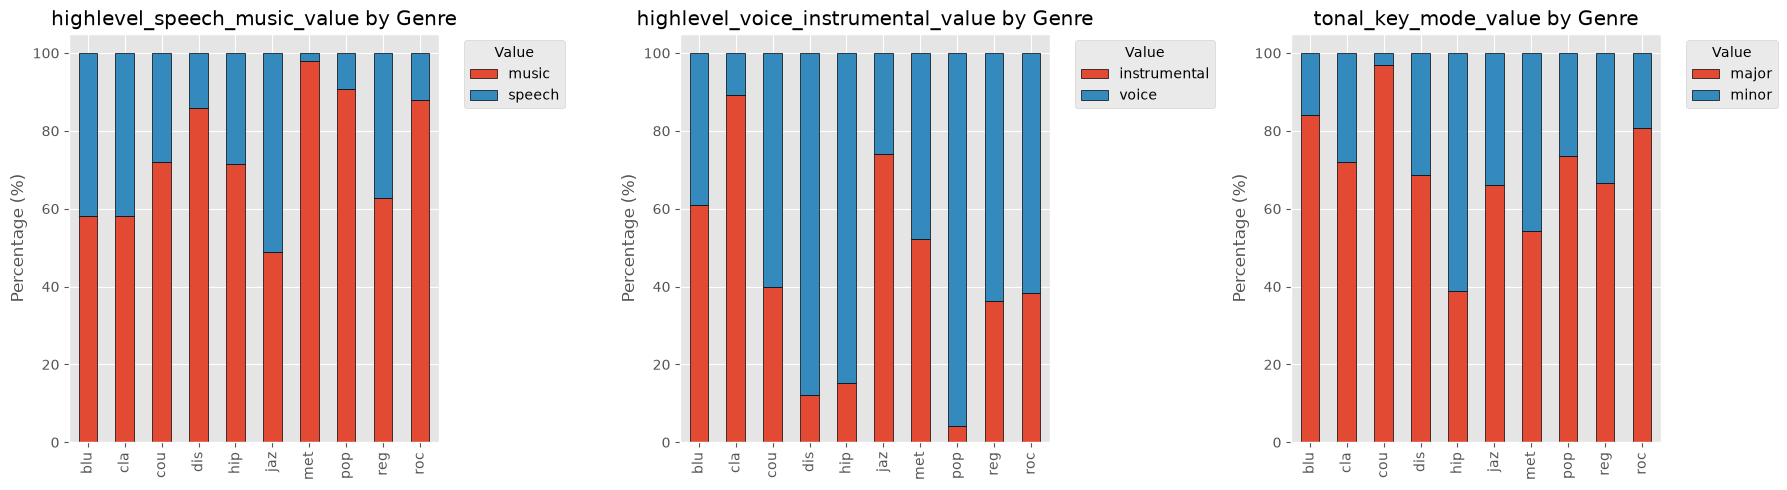

In [19]:
#cross-tabulation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(binary_cols_names):
    crosstab = pd.crosstab(genre_df[target_col_name], genre_df[col], normalize='index')*100
    crosstab.plot(kind='bar', stacked=True, ax=axes[i], edgecolor='black')

    axes[i].set_title(f'{col} by Genre')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel('')
    axes[i].legend(title='Value', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

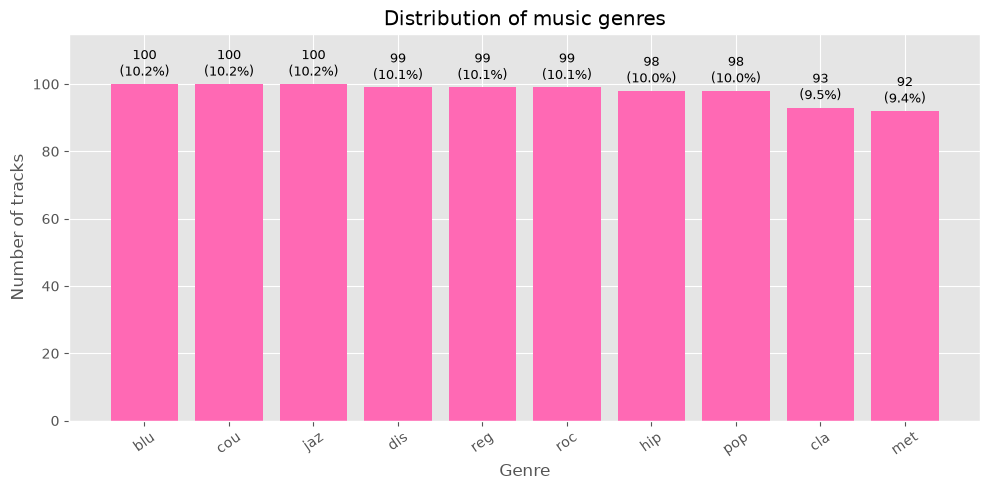

In [20]:
#target column distribution
# genre_df['genre'].value_counts(normalize=True) * 100. If "Pop" makes up 40% of your dataset and "Jazz" is only 2%, 
# standard algorithms will just blindly guess "Pop" to get an artificially high accuracy score. You need to know this before you train anything.
counts = genre_df[target_col_name].value_counts()
total = counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color="hotpink")
ax.bar_label(
    bars,
    labels=[f"{count}\n({count / total:.1%})" for count in counts.values],
    padding=3,
    fontsize=9,
)
ax.set(
    title="Distribution of music genres",
    xlabel="Genre",
    ylabel="Number of tracks",
)
ax.tick_params(axis="x", rotation=35)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

The genres are slightly unbalanced. Adjusting class weights could be helpful but not crucial.

Todo
- sns.pairplot(df, vars=[...], hue=)
- sns.heatmaps(, annot=True)
- sns.scatterplot(x=col, y-col, data-df, hue=col)
- mutual information/correlation

## 2. Feature Engineering

In [21]:
import sklearn
sklearn.set_config(transform_output="pandas")
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OrdinalEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

In [22]:
genre_df.head(5)

,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_mean,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean,spectral_mfcc_00_var,spectral_mfcc_01_dvar,spectral_

To accomodate possible outliers we will use Robust Scaler

In [23]:
# scaling and encoding
cat_columns = cat_columns.drop("genre")
print(cat_columns.shape)

scaler_and_encoder = ColumnTransformer(
    transformers=[
    ('num', RobustScaler(), num_columns),
    ('cat', OrdinalEncoder(), cat_columns)
])

(3,)


In [24]:
#filtering out the correlations higher than threshold, leaving the one that has higher correlation with target value

class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.85):
        self.threshold = threshold
        self.to_drop_ = []

    def fit(self, X, y):
        # Ponieważ używamy transform_output="pandas", X jest już DataFrame'em
        corr_matrix = X.corr().abs()
        
        # Maska dla górnego trójkąta macierzy
        upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        
        # POPRAWKA 1: Używamy .loc[row, column] zamiast [row, column]
        high_corr_pairs = [(column, row) for column in upper.columns for row in upper.index if upper.loc[row, column] > self.threshold]
        
        # POPRAWKA 2: Przypisujemy indeksy z X do y, żeby Pandas poprawnie policzył korelację po train_test_split
        target_series = pd.Series(y, index=X.index)
        
        for col, row in high_corr_pairs:
            corr_col = X[col].corr(target_series)
            corr_row = X[row].corr(target_series)
            
            if abs(corr_col) < abs(corr_row):
                if col not in self.to_drop_:
                    self.to_drop_.append(col)
            else:
                if row not in self.to_drop_:
                    self.to_drop_.append(row)
                    
        return self

    def transform(self, X):
        # Zwracamy DataFrame, żeby SelectKBest też miał nazwy kolumn
        return X.drop(columns=[col for col in self.to_drop_ if col in X.columns])

In [25]:
#LR, kNN, ANN
preprocessor_1 = Pipeline(steps=[
    ('scaler_and_labeler', scaler_and_encoder),
    ('corr_filter', CorrelationFilter(threshold=0.9)),
    ('feature_selection', SelectKBest(score_func=f_classif, k=40))
])

#Trees, XGB
preprocessor_2 = Pipeline(steps=[
    ('scaler_and_labeler', scaler_and_encoder)
])

## 3. Classification

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
import torch


Train test split

In [27]:
#encoding the target column into integers
le = LabelEncoder()
y = le.fit_transform(genre_df['genre'])

In [28]:
X = genre_df.drop(columns=["genre"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Sizes of the train/test splits\n")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Sizes of the train/test splits

X_train: (782, 238)
X_test: (196, 238)
y_train: (782,)
y_test: (196,)


In [ ]:
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print("Training on:", device)

### Logistic Regression

In [ ]:
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_1),
    ('classifier', LogisticRegression(class_weight='balanced', solver='saga', max_iter=2000, random_state=42))
])

#for finetuning
param_grid = {
    'preprocessor__feature_selection__k': [20, 40, 60, 'all'], 
    'classifier__C': [0.01, 0.1, 1.0, 10.0], 
    'classifier__penalty': ['elasticnet'],
    'classifier__l1_ratio': [0.0, 1.0]# 1.0 is L1 (Lasso) acts as native feature selection and handles un-deleted outliers safely, 0.0 is L2 (Ridge)
}

#stratified cross-validation
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    return_train_score=True,
    n_jobs=-1
)

#train

lr_search.fit(X_train, y_train)

/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instea

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__l1_ratio': [0.0, 1.0], 'classifier__penalty': ['elasticnet'], 'preprocessor__feature_selection__k': [20, 40, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,`

### kNN

In [32]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", KNeighborsClassifier()),
])

param_grid = {
    "preprocessor__feature_selection__k": [20, 40, 60, "all"],
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "classifier__weights": ["uniform", "distance"],
    "classifier__metric": ["minkowski"],
    "classifier__p": [1, 2],  # 1 = Manhattan, 2 = Euclidean
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1,
)

knn_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__metric': ['minkowski'], 'classifier__n_neighbors': [3, 5, ...], 'classifier__p': [1, 2], 'classifier__weights': ['uniform', 'distance'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_sc

### Decition Tree

In [34]:
dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", DecisionTreeClassifier(random_state=42)),
])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


dt_param_grid = {
    "preprocessor__feature_selection__k": [20, 40, 60, "all"],
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5],
}

dt_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1,
)

dt_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [None, 5, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'preprocessor__feature_selection__k': [20, 40, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attrib

In [35]:
print("Random Forest best CV accuracy:", dt_search.best_score_)

Random Forest best CV accuracy: 0.615141187925998


### Random Forest

In [36]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1,  # GridSearchCV handles parallelism
    )),
])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rf_param_grid = {
    "preprocessor__feature_selection__k": [20, 40, 60, "all"],
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__max_features": ["sqrt", 0.5],
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1,
)

rf_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [None, 10, ...], 'classifier__max_features': ['sqrt', 0.5], 'classifier__min_samples_leaf': [1, 2], 'classifier__n_estimators': [100, 300], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_ind

In [37]:
print("Random Forest best parameters:", rf_search.best_params_)
print("Random Forest best CV accuracy:", rf_search.best_score_)

Random Forest best parameters: {'classifier__max_depth': None, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100, 'preprocessor__feature_selection__k': 'all'}
Random Forest best CV accuracy: 0.8006004543979227


### ANN (MLP)

In [38]:
mlp_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", MLPClassifier(
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42,
    )),
])

mlp_param_grid = {
    "preprocessor__feature_selection__k": [20, 40, 60, "all"],
    "classifier__hidden_layer_sizes": [(64,), (128,), (64, 32)],
    "classifier__alpha": [0.0001, 0.01],
    "classifier__learning_rate_init": [0.001, 0.01],
}

mlp_search = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1,
)

mlp_search.fit(X_train, y_train)

print("MLP best parameters:", mlp_search.best_params_)
print("MLP best CV accuracy:", mlp_search.best_score_)


MLP best parameters: {'classifier__alpha': 0.01, 'classifier__hidden_layer_sizes': (128,), 'classifier__learning_rate_init': 0.01, 'preprocessor__feature_selection__k': 60}
MLP best CV accuracy: 0.7992372606296657


The Split Strategy (Solving RQ1)
You cannot use a standard train_test_split. To prove if the 3-second accuracy is inflated by data leakage, you must build two separate splitters. Use StratifiedKFold for the "naive" baseline that allows leakage, and GroupKFold (using the parent track ID as the grouping key) to force all 3-second slices of the same song strictly into either the training or testing set.

Class Weight Balancing
If your EDA showed that some genres have significantly more tracks than others, models will artificially inflate their accuracy by over-predicting the majority class. Do not use synthetic oversampling (like SMOTE) on high-dimensional audio features. Instead, simply pass the class_weight='balanced' parameter into Logistic Regression, Decision Trees, and Random Forests. XGBoost uses scale_pos_weight for a similar effect.

Hyperparameter Boundaries
Never evaluate default algorithms against each other. A default Decision Tree will grow infinitely deep and memorize the training data (maximum overfitting), while a default ANN might fail to converge at all. You need to wrap your models in a RandomizedSearchCV to find their optimal configurations.

Outliers ---
Musisz tylko pamiętać, aby przy konfiguracji Regresji Logistycznej lub Sieci Neuronowej (ANN) użyć regularyzacji L1 (Lasso) lub absolutnej funkcji błędu (MAE), aby gradient nie oszalał na tych pozostawionych anomaliach

Early stopping

## 4. Evaluation

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

In [ ]:
for name, search in [
    ("Decision Tree", dt_search),
    ("Random Forest", rf_search),
]:
    y_pred = search.predict(X_test)
    print(f"\n{name} test accuracy: {accuracy_score(y_test, y_pred):.3f}")
    print(classification_report(y_test, y_pred))

In [ ]:
# Pobranie indeksu najlepszego modelu, aby wyciągnąć jego wynik treningowy
best_idx = lr_search.best_index_
cv_train_score = lr_search.cv_results_['mean_train_score'][best_idx]
cv_val_score = lr_search.best_score_

print(f"Najlepsze hiperparametry: {lr_search.best_params_}")
print(f"Średnia dokładność na foldach treningowych (CV): {cv_train_score:.4f}")
print(f"Średnia dokładność na foldach walidacyjnych (CV): {cv_val_score:.4f}")

# Ostateczna ewaluacja na odłożonym zbiorze testowym
test_score = lr_search.score(X_test, y_test)
print(f"\nDokładność na niewidzianym X_test: {test_score:.4f}")

# Szczegółowy raport z odkodowanymi nazwami gatunków
y_pred = lr_search.predict(X_test)
print("\nRaport klasyfikacji per gatunek:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Najlepsze hiperparametry: {'classifier__C': 1.0, 'classifier__l1_ratio': 1.0, 'classifier__penalty': 'elasticnet', 'preprocessor__feature_selection__k': 60}
Średnia dokładność na foldach treningowych (CV): 0.9322
Średnia dokładność na foldach walidacyjnych (CV): 0.8249

Dokładność na niewidzianym X_test: 0.8265

Raport klasyfikacji per gatunek:
              precision    recall  f1-score   support

         blu       0.81      0.85      0.83        20
         cla       1.00      1.00      1.00        18
         cou       0.71      0.75      0.73        20
         dis       0.80      0.80      0.80        20
         hip       0.94      0.85      0.89        20
         jaz       0.81      0.85      0.83        20
         met       0.94      0.94      0.94        18
         pop       0.84      0.80      0.82        20
         reg       0.79      0.75      0.77        20
         roc       0.67      0.70      0.68        20

    accuracy                           0.83       196
   

In [33]:
# Pobranie indeksu najlepszego modelu, aby wyciągnąć jego wynik treningowy
best_idx = knn_search.best_index_
cv_train_score = knn_search.cv_results_['mean_train_score'][best_idx]
cv_val_score = knn_search.best_score_

print(f"Najlepsze hiperparametry: {knn_search.best_params_}")
print(f"Średnia dokładność na foldach treningowych (CV): {cv_train_score:.4f}")
print(f"Średnia dokładność na foldach walidacyjnych (CV): {cv_val_score:.4f}")

# Ostateczna ewaluacja na odłożonym zbiorze testowym
test_score = knn_search.score(X_test, y_test)
print(f"\nDokładność na niewidzianym X_test: {test_score:.4f}")

# Szczegółowy raport z odkodowanymi nazwami gatunków
y_pred = knn_search.predict(X_test)
print("\nRaport klasyfikacji per gatunek:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Najlepsze hiperparametry: {'classifier__metric': 'minkowski', 'classifier__n_neighbors': 7, 'classifier__p': 2, 'classifier__weights': 'distance', 'preprocessor__feature_selection__k': 60}
Średnia dokładność na foldach treningowych (CV): 1.0000
Średnia dokładność na foldach walidacyjnych (CV): 0.7532

Dokładność na niewidzianym X_test: 0.7704

Raport klasyfikacji per gatunek:
              precision    recall  f1-score   support

         blu       0.73      0.80      0.76        20
         cla       0.86      1.00      0.92        18
         cou       0.72      0.90      0.80        20
         dis       0.78      0.70      0.74        20
         hip       0.78      0.70      0.74        20
         jaz       0.93      0.70      0.80        20
         met       0.89      0.89      0.89        18
         pop       0.72      0.65      0.68        20
         reg       0.68      0.65      0.67        20
         roc       0.68      0.75      0.71        20

    accuracy             

todo
- prunning DT and RF


# Task 2

## 1. Data loading and EDA

In [6]:
f30_df = pd.read_csv("./data/features_30_sec.csv", sep=",")
f30_df.columns = f30_df.columns.str.strip() #erase the whitespaces
feature_colnames_30 = f30_df.columns.drop('label').tolist()

print(f"Shape: {f30_df.shape[0]} rows, {f30_df.shape[1]} columns\n")
f30_df.head(10)

Shape: 1000 rows, 60 columns



,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,1.297741e+05,2002.449060,85882.761315,3805.839606,9.015054e+05,0.083045,0.000767,-4.529724e-05,0.008172,0.000008,0.005698,123.046875,-113.570648,2564.207520,121.571793,295.913818,-19.168142,235.574432,42.366421,151.106873,-6.364664,167.934799,18.623499,89.180840,-13.704891,67.660492,15.343150,68.932579,-12.274110,82.204201,10.976572,63.386311,-8.326573,61.773094,8.803792,51.244125,-3.672300,41.217415,5.747995,40.554478,-5.162882,49.775421,0.752740,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,3.758501e+05,2039.036516,213843.755497,3550.522098,2.977893e+06,0.056040,0.001448,1.395807e-04,0.005099,-0.000178,0.003063,67.999589,-207.501694,7764.555176,123.991264,560.259949,8.955127,572.810913,35.877647,264.506104,2.907320,279.932922,21.510466,156.477097,-8.560436,200.849182,23.370686,142.555954,-10.099661,166.108521,11.900497,104.358612,-5.555639,105.173630,5.376327,96.197212,-2.231760,64.914291,4.220140,73.152534,-6.012148,52.422142,0.927998,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,1.564676e+05,1747.702312,76254.192257,3042.260232,7.840345e+05,0.076291,0.001007,2.105576e-06,0.016342,-0.000019,0.007458,161.499023,-90.722595,3319.044922,140.446304,508.765045,-29.093889,411.781219,31.684334,144.090317,-13.984504,155.493759,25.764742,74.548401,-13.664875,106.981827,11.639934,106.574875,-11.783643,65.447945,9.718760,67.908859,-13.133803,57.781425,5.791199,64.480209,-8.907628,60.385151,-1.077000,57.711136,-9.229274,36.580986,2.451690,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,1.843559e+05,1596.412872,166441.494769,2184.745799,1.493194e+06,0.033309,0.000423,4.583644e-07,0.019054,-0.000014,0.002712,63.024009,-199.544205,5507.517090,150.090897,456.505402,5.662678,257.161163,26.859079,158.267303,1.771399,268.034393,14.234031,126.794128,-4.832006,155.912079,9.286494,81.273743,-0.759186,92.114090,8.137607,71.314079,-3.200653,110.236687,6.079319,48.251999,-2.480174,56.799400,-1.079305,62.289902,-2.870789,51.651592,0.780874,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,3.433999e+05,1748.172116,88445.209036,3579.757627,1.572978e+06,0.101461,0.001954,-1.756129e-05,0.004814,-0.000010,0.003094,135.999178,-160.337708,5195.291992,126.219635,853.784729,-35.587811,333.792938,22.148071,193.456100,-32.478600,336.276825,10.852294,134.831573,-23.352329,93.257095,0.498434,124.672127,-11.793437,130.073349,1.207256,99.675575,-13.088418,80.254066,-2.813867,86.430626,-6.933385,89.555443,-7.552725,70.943336,-9.164666,75.793404,-4.520576,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues
5,blues.00005.wav,661794,0.302456,0.087532,0.103494,0.003981,1831.993940,1.030482e+06,1729.653287,201910.508633,3481.517592,3.274440e+06,0.094042,0.0062

In [7]:
f3_df = pd.read_csv("./data/features_3_sec.csv", sep=",")
f3_df.columns = f3_df.columns.str.strip() #erase the whitespaces
feature_colnames_3 = f3_df.columns.drop('label').tolist()

print(f"Shape: {f3_df.shape[0]} rows, {f3_df.shape[1]} columns\n")
f3_df.head(10)

Shape: 9990 rows, 60 columns



,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,3714.560359,1.080790e+06,0.081851,0.000558,-0.000078,0.008354,-0.000068,0.005535,129.199219,-118.627914,2440.286621,125.083626,260.956909,-23.443724,364.081726,41.321484,181.694855,-5.976108,152.963135,20.115141,75.652298,-16.045410,40.227104,17.855198,84.320282,-14.633434,83.437233,10.270527,97.001335,-9.708279,66.669891,10.183875,45.103611,-4.681614,34.169498,8.417439,48.269444,-7.233477,42.770947,-2.853603,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,3869.682242,6.722448e+05,0.087173,0.001030,-0.000099,0.004950,-0.000103,0.004854,123.046875,-125.590706,2038.344238,122.421227,216.774185,-20.718019,231.979767,50.128387,142.700409,-11.333302,139.243118,21.385401,77.817947,-15.960796,97.364029,19.454103,57.948093,-12.465918,68.271523,17.898169,56.222176,-11.732554,54.373909,8.145000,40.662876,-7.717751,30.808521,8.397150,48.784225,-8.300493,68.584824,4.074709,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,3997.639160,7.907127e+05,0.071383,0.000425,-0.000066,0.012476,0.000065,0.004357,123.046875,-132.441940,3798.532227,115.085175,257.321289,-14.811666,192.448074,50.189293,144.166031,-0.680819,128.376892,24.650375,66.371170,-13.506104,89.319336,15.643386,55.253967,-13.216637,120.308784,10.406025,35.757862,-7.991465,47.911613,11.853963,36.569931,-4.677677,40.725075,6.571110,30.686846,-2.424750,50.313499,4.806280,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,3568.300218,9.216524e+05,0.069426,0.000304,-0.000014,0.008318,0.000018,0.005927,123.046875,-118.231087,2508.781006,132.116501,332.650574,-18.758335,109.357529,39.769306,184.693344,-13.260426,144.398224,20.468134,122.516464,-14.563448,68.937332,18.745104,74.748886,-13.755463,73.868576,12.993759,41.549564,-12.648887,58.540478,10.389314,39.102024,-4.362739,60.714748,9.156193,40.411537,-9.889441,44.666325,-1.359111,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,3469.992864,6.102111e+05,0.070095,0.000289,0.000041,0.009634,-0.000106,0.005833,123.046875,-105.968376,2118.919922,134.643646,219.562622,-19.961748,171.878754,40.171753,103.120712,-14.271939,102.651230,18.734617,79.070000,-15.619381,48.510284,19.207966,53.642956,-18.274683,95.300995,14.316693,58.821163,-5.792194,55.030254,17.045437,43.229939,-5.681399,46.515259,5.705521,24.956211,-7.986080,39.816933,2.092937,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues
5,blues.00000.5.wav,66149,0.376670,0.089702,0.132618,0.003583,1994.915219,211700.619569,2152.767854,74263.873102,4371.985614,1.067105e+06,0.092420,0.001174,-0.00003